# Mathematical Morphological Image Processing

A custom Python implementation of **binary mathematical morphology** for image processing, based on the methodology presented in the reference paper:

> **A Study on Image Processing Using Mathematical Morphological**
> K. A. M. Said and A. B. Jambek, 2016 3rd International Conference on Electronic Design (ICED).

## Reference Method

The primary implementation follows the paper's binary mathematical morphology workflow:

**Input Image → Grayscale → Binary Image → Structuring Element (SE) → Erosion → Dilation → Opening → Closing → White Top-Hat → Black Top-Hat → Mathematical Morphological Output → SE Comparison**

The main mathematical operations are defined as:

* **Opening** = Erosion followed by Dilation
* **Closing** = Dilation followed by Erosion
* **White Top-Hat (WTH)** = `IM − Opening`
* **Black Top-Hat (BTH)** = `Closing − IM`
* **Final Morphological Output** = `IM + WTH − BTH`

The reference paper applies the morphological operations to a **binary image** using rectangular structuring elements and evaluates several SE configurations, including **3 × 8, 4 × 8, 5 × 8, and 6 × 8**. A **4 × 8 rectangular SE** is selected in the paper for its particular input image.

## Implementation

The core morphological operations are implemented using **custom Python functions** rather than existing built-in morphology operations.

The implementation does not use:

* OpenCV erosion or dilation functions
* OpenCV morphological operations
* SciPy binary morphology
* `sliding_window_view`
* `einsum`

for the core erosion and dilation implementation.

The morphology operations are implemented directly using the structuring element and pixel-level logical operations, providing explicit control over the algorithm.

## Processing Modes

Two processing configurations are available:

### 1. Reference / Binary Mode

The primary mode follows the **binary mathematical morphology workflow described in the reference paper**.

It includes:

* Custom grayscale conversion
* Custom Otsu thresholding
* Binary image generation
* Rectangular structuring element
* Custom erosion
* Custom dilation
* Opening
* Closing
* White Top-Hat
* Black Top-Hat
* Final morphological recombination
* Structuring-element comparison

### 2. Adaptive / Grayscale Extension

An additional engineering extension is provided for broader experimentation.

This mode:

* Preserves the same morphological concepts
* Supports grayscale intensity information
* Allows dynamically selected structuring-element dimensions
* Provides an alternative configuration for images with different resolutions

This grayscale/adaptive functionality is an **extension of the implementation** and is not presented as a claim about the methodology used in the reference paper.

## Purpose

The project demonstrates how fundamental mathematical morphology operations can be implemented **from scratch**, while maintaining a clear connection between the mathematical definitions, algorithmic implementation, experimental configuration, and resulting image transformations.


## 1. Method / Technique Applied

### 1.1 Binary Mathematical Morphology

The primary implementation uses **binary mathematical morphology**, where:

* Background = `0`
* Foreground = `1`

For each active position of the structuring element (SE), **erosion** requires all corresponding image pixels to be foreground, while **dilation** requires at least one corresponding image pixel to be foreground.

The compound morphological operations are:

```text
Opening = Erosion → Dilation

Closing = Dilation → Erosion
```

The top-hat transformations are:

```text
White Top-Hat = Input − Opening

Black Top-Hat = Closing − Input
```

The final morphological expression follows the reference paper:

```text
Output = Input + White Top-Hat − Black Top-Hat
```

For binary input, this recombination can reconstruct the original binary image. Therefore, the intermediate results—particularly erosion, dilation, opening, closing, WTH, and BTH—are important for observing the structural effects produced by the selected SE.

### 1.2 Structuring Element Strategy

The implementation supports two structuring-element configurations:

* **Paper SE:** a fixed `4 × 8` rectangular SE corresponding to the primary configuration used in the reference paper.
* **Adaptive SE:** a dynamically derived rectangular SE based on the input image dimensions while maintaining approximately the same `1:2` height-to-width relationship.

The adaptive configuration also applies size bounds to prevent excessively large structuring elements when processing very small or very large images.

The fixed **4 × 8** configuration is used as the primary paper-oriented setting, while adaptive selection is provided as an additional engineering feature for reusable image processing.

### 1.3 Grayscale Morphology Extension

The implementation also provides an optional grayscale morphology mode.

For grayscale images:

* **Erosion** uses the minimum intensity value among the active SE positions.
* **Dilation** uses the maximum intensity value among the active SE positions.

Unlike binary processing, grayscale morphology preserves continuous intensity information that would otherwise be discarded during binarization. This allows opening, closing, White Top-Hat, and Black Top-Hat operations to be explored directly in the intensity domain.

The grayscale and adaptive functionality is explicitly treated as an **implementation extension** and is separate from the primary binary morphology workflow used for reproducing the reference method.


## 2. Required Image / Input

The notebook accepts a **user-selected input image** rather than depending on a fixed filename such as `Input_image.jpg`. The input is detected and processed automatically after upload.

### Supported Formats

The implementation supports common image formats, including:

* JPEG / JPG
* PNG
* BMP
* TIFF / TIF
* WEBP

### Colab Input

In Google Colab, run the input cell and upload any supported image. The notebook automatically detects the uploaded filename and uses it as the processing input.

### Local / Jupyter Input

For local or Jupyter execution, set `LOCAL_IMAGE_PATH` to the desired image path and configure:

```text
USE_COLAB_UPLOAD = False
```

This allows the same implementation to be used outside Google Colab without modifying the core processing functions.

### Image Resolution

The implementation does not require a fixed image resolution. The input dimensions are detected automatically.

When adaptive SE selection is enabled, the structuring element is derived from the image dimensions while maintaining the intended aspect-ratio relationship and applying appropriate size bounds.

### Reproducibility

For reproduction of the primary reference-paper configuration, use:

```text
SE_MODE = "paper"
PAPER_SE = (4, 8)
PROCESSING_MODE = "binary"
```

This configuration uses the fixed **4 × 8 rectangular structuring element** and binary processing mode, providing a consistent baseline for reproducing the main experiment.


In [1]:
# ============================================================
# 3. Environment and Configuration
# ============================================================

from pathlib import Path
from typing import Dict, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# -----------------------------
# Input configuration
# -----------------------------

USE_COLAB_UPLOAD = True

# Used when USE_COLAB_UPLOAD = False.
LOCAL_IMAGE_PATH = Path("Input_image.jpg")

# -----------------------------
# Processing configuration
# -----------------------------

# "binary"    -> reference-paper workflow
# "grayscale" -> intensity-domain extension
PROCESSING_MODE = "binary"

# "paper"     -> exact 4 x 8 SE from the reference paper
# "adaptive"  -> dynamically derived from image dimensions
SE_MODE = "paper"

PAPER_SE = (4, 8)

# Adaptive SE configuration.
# The reference SE has a 1:2 height:width ratio.
ADAPTIVE_HEIGHT_RATIO = 0.006
ADAPTIVE_MIN_HEIGHT = 3
ADAPTIVE_MAX_HEIGHT = 31
ADAPTIVE_WIDTH_RATIO = 2.0

# Comparison required by the reference experiment.
REFERENCE_SE_CANDIDATES = [
    (3, 8),
    (4, 8),
    (5, 8),
    (6, 8),
]

# -----------------------------
# Numerical / visualization
# -----------------------------

DISPLAY_MAX_SIDE = 1400

SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

print("Configuration loaded.")
print(f"Processing mode : {PROCESSING_MODE}")
print(f"SE mode         : {SE_MODE}")


Configuration loaded.
Processing mode : binary
SE mode         : paper


In [2]:
# ============================================================
# 4. Input Handling
# ============================================================

def upload_image_from_colab() -> Path:
    """
    Upload an image interactively in Google Colab.

    The user selects the file; no hardcoded filename is required.
    """
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError(
            "Colab upload is enabled, but this notebook is not running "
            "inside Google Colab. Set USE_COLAB_UPLOAD = False for local use."
        ) from exc

    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No image was uploaded.")

    uploaded_names = [
        name for name in uploaded
        if Path(name).suffix.lower() in SUPPORTED_EXTENSIONS
    ]

    if not uploaded_names:
        raise ValueError(
            "No supported image file was uploaded. "
            f"Supported extensions: {sorted(SUPPORTED_EXTENSIONS)}"
        )

    # Deterministic selection if multiple valid images are uploaded.
    selected_name = sorted(uploaded_names)[0]
    return Path(selected_name)


def resolve_input_path() -> Path:
    """
    Resolve the input image from Colab upload or local configuration.
    """
    if USE_COLAB_UPLOAD:
        path = upload_image_from_colab()
    else:
        path = Path(LOCAL_IMAGE_PATH)

    if not path.exists():
        raise FileNotFoundError(f"Image not found: {path}")

    if path.suffix.lower() not in SUPPORTED_EXTENSIONS:
        raise ValueError(
            f"Unsupported image format: {path.suffix}. "
            f"Supported extensions: {sorted(SUPPORTED_EXTENSIONS)}"
        )

    return path


def load_rgb_image(path: Path) -> np.ndarray:
    """
    Load an image as an RGB uint8 array.

    PIL is used only for file decoding. Morphological processing
    is implemented separately by this notebook.
    """
    with Image.open(path) as image:
        rgb = image.convert("RGB")
        array = np.asarray(rgb, dtype=np.uint8)

    if array.ndim != 3 or array.shape[2] != 3:
        raise ValueError("Decoded image is not a valid RGB image.")

    return array


def rgb_to_grayscale(rgb: np.ndarray) -> np.ndarray:
    """
    Convert RGB to grayscale using the standard luminance coefficients.

    This conversion is implemented directly rather than using an
    image-processing library conversion function.
    """
    rgb = np.asarray(rgb)

    if rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError("RGB input must have shape (height, width, 3).")

    rgb_float = rgb.astype(np.float32)

    gray = (
        0.299 * rgb_float[:, :, 0]
        + 0.587 * rgb_float[:, :, 1]
        + 0.114 * rgb_float[:, :, 2]
    )

    return np.clip(np.rint(gray), 0, 255).astype(np.uint8)


IMAGE_PATH = resolve_input_path()
RGB_IMAGE = load_rgb_image(IMAGE_PATH)
GRAY_IMAGE = rgb_to_grayscale(RGB_IMAGE)

print(f"Input file      : {IMAGE_PATH.name}")
print(f"Image dimensions: {GRAY_IMAGE.shape[0]} × {GRAY_IMAGE.shape[1]}")
print(f"Color channels  : {RGB_IMAGE.shape[2]}")


Saving Input_image.jpg to Input_image.jpg
Input file      : Input_image.jpg
Image dimensions: 320 × 320
Color channels  : 3


In [3]:
# ============================================================
# 5. Custom Otsu Thresholding
# ============================================================

def otsu_threshold(gray: np.ndarray) -> int:
    """
    Compute Otsu's global threshold from scratch.

    No OpenCV/scikit-image threshold function is used.

    Returns an integer threshold in [0, 255].
    """
    gray = np.asarray(gray)

    if gray.ndim != 2:
        raise ValueError("Otsu thresholding requires a 2D grayscale image.")

    if gray.dtype != np.uint8:
        gray = np.clip(gray, 0, 255).astype(np.uint8)

    histogram = np.bincount(
        gray.ravel(),
        minlength=256
    ).astype(np.float64)

    total_pixels = gray.size
    intensity_levels = np.arange(256, dtype=np.float64)

    total_weighted_sum = np.sum(
        intensity_levels * histogram
    )

    background_weight = 0.0
    background_sum = 0.0

    best_threshold = 0
    best_between_class_variance = -1.0

    for threshold in range(256):
        background_weight += histogram[threshold]

        if background_weight == 0:
            continue

        foreground_weight = total_pixels - background_weight

        if foreground_weight == 0:
            break

        background_sum += (
            threshold * histogram[threshold]
        )

        background_mean = (
            background_sum / background_weight
        )

        foreground_mean = (
            (total_weighted_sum - background_sum)
            / foreground_weight
        )

        between_class_variance = (
            background_weight
            * foreground_weight
            * (background_mean - foreground_mean) ** 2
        )

        if between_class_variance > best_between_class_variance:
            best_between_class_variance = between_class_variance
            best_threshold = threshold

    return int(best_threshold)


def binarize(gray: np.ndarray, threshold: int) -> np.ndarray:
    """
    Convert grayscale intensities to a binary 0/1 image.
    """
    gray = np.asarray(gray)

    if gray.ndim != 2:
        raise ValueError("Input must be a 2D grayscale image.")

    return (gray >= threshold).astype(np.uint8)


OTSU_THRESHOLD = otsu_threshold(GRAY_IMAGE)
BINARY_IMAGE = binarize(GRAY_IMAGE, OTSU_THRESHOLD)

print(f"Custom Otsu threshold: {OTSU_THRESHOLD}")
print(f"Foreground pixels    : {np.count_nonzero(BINARY_IMAGE):,}")
print(f"Background pixels    : {BINARY_IMAGE.size - np.count_nonzero(BINARY_IMAGE):,}")


Custom Otsu threshold: 130
Foreground pixels    : 63,383
Background pixels    : 39,017


In [4]:
# ============================================================
# 6. Dynamic Structuring Element
# ============================================================

def rectangular_structuring_element(
    height: int,
    width: int
) -> np.ndarray:
    """
    Create a binary rectangular structuring element.

    The SE is represented using 0/1 values.
    """
    if height < 1 or width < 1:
        raise ValueError("SE dimensions must be positive integers.")

    return np.ones(
        (int(height), int(width)),
        dtype=np.uint8
    )


def adaptive_se_shape(
    image_shape: Tuple[int, int],
    height_ratio: float = ADAPTIVE_HEIGHT_RATIO,
    min_height: int = ADAPTIVE_MIN_HEIGHT,
    max_height: int = ADAPTIVE_MAX_HEIGHT,
    width_ratio: float = ADAPTIVE_WIDTH_RATIO,
) -> Tuple[int, int]:
    """
    Derive an SE size from image dimensions.

    The height scales with image height and the width keeps the
    approximately 1:2 aspect ratio used by the reference SE.

    The size is bounded for stability on very small/large images.
    """
    image_height, image_width = image_shape

    if image_height < 1 or image_width < 1:
        raise ValueError("Image dimensions must be positive.")

    height = int(round(image_height * height_ratio))
    height = max(min_height, height)
    height = min(max_height, height)

    # Keep the kernel inside the image.
    height = min(height, image_height)
    width = int(round(height * width_ratio))
    width = max(1, min(width, image_width))

    return height, width


def build_structuring_element(
    image_shape: Tuple[int, int],
    mode: str
) -> np.ndarray:
    """
    Build either the exact paper SE or a resolution-aware SE.
    """
    mode = mode.lower().strip()

    if mode == "paper":
        height, width = PAPER_SE
    elif mode == "adaptive":
        height, width = adaptive_se_shape(image_shape)
    else:
        raise ValueError("SE mode must be 'paper' or 'adaptive'.")

    return rectangular_structuring_element(height, width)


SE = build_structuring_element(
    GRAY_IMAGE.shape,
    SE_MODE
)

print(f"Selected SE mode : {SE_MODE}")
print(f"Selected SE size : {SE.shape[0]} × {SE.shape[1]}")


Selected SE mode : paper
Selected SE size : 4 × 8


In [5]:
# ============================================================
# 7. Custom Mathematical Morphology
# ============================================================

class MathematicalMorphology:
    """
    Custom mathematical morphology implementation.

    Core operations are implemented directly with NumPy array
    operations and explicit SE-position iteration.

    No OpenCV/SciPy morphology function is used.

    Supported modes:
        - binary
        - grayscale
    """

    def __init__(self, structuring_element: np.ndarray):
        se = np.asarray(structuring_element)

        if se.ndim != 2 or se.size == 0:
            raise ValueError("SE must be a non-empty 2D array.")

        if not np.all(np.isin(se, [0, 1])):
            raise ValueError("SE must contain only 0 and 1.")

        if not np.any(se):
            raise ValueError("SE must contain at least one active position.")

        self.se = se.astype(np.uint8)
        self.height, self.width = self.se.shape

        # Explicit deterministic anchor convention.
        # For even-sized SEs, floor(dimension / 2) is used.
        # This matches the conventional center-index choice used by
        # common morphology implementations.
        self.anchor_row = self.height // 2
        self.anchor_col = self.width // 2

        self.active_offsets = [
            (
                row - self.anchor_row,
                col - self.anchor_col
            )
            for row in range(self.height)
            for col in range(self.width)
            if self.se[row, col] == 1
        ]

    def _validate_grayscale(self, image: np.ndarray) -> np.ndarray:
        image = np.asarray(image)

        if image.ndim != 2:
            raise ValueError("Image must be a 2D array.")

        if image.size == 0:
            raise ValueError("Image cannot be empty.")

        if image.dtype != np.uint8:
            image = np.clip(image, 0, 255).astype(np.uint8)

        return image

    def _validate_binary(self, image: np.ndarray) -> np.ndarray:
        image = np.asarray(image)

        if image.ndim != 2:
            raise ValueError("Binary image must be a 2D array.")

        if image.size == 0:
            raise ValueError("Binary image cannot be empty.")

        if not np.all((image == 0) | (image == 1)):
            raise ValueError("Binary image must contain only 0 and 1.")

        return image.astype(np.uint8)

    def _shifted_view(
        self,
        image: np.ndarray,
        row_offset: int,
        col_offset: int,
        fill_value: int
    ) -> np.ndarray:
        """
        Return an image aligned to the current output coordinate system.

        For every output coordinate (r, c), the returned array contains
        image[r + row_offset, c + col_offset] when that source coordinate
        exists. Pixels outside the image domain receive fill_value.

        This explicit implementation replaces library
        morphology/window functions.
        """
        height, width = image.shape

        output = np.full(
            (height, width),
            fill_value,
            dtype=image.dtype
        )

        source_row_start = max(0, row_offset)
        source_row_end = min(height, height + row_offset)
        source_col_start = max(0, col_offset)
        source_col_end = min(width, width + col_offset)

        target_row_start = max(0, -row_offset)
        target_row_end = target_row_start + (
            source_row_end - source_row_start
        )

        target_col_start = max(0, -col_offset)
        target_col_end = target_col_start + (
            source_col_end - source_col_start
        )

        if (
            source_row_end > source_row_start
            and source_col_end > source_col_start
        ):
            output[
                target_row_start:target_row_end,
                target_col_start:target_col_end
            ] = image[
                source_row_start:source_row_end,
                source_col_start:source_col_end
            ]

        return output

    def erosion_binary(self, image: np.ndarray) -> np.ndarray:
        """
        Binary erosion.

        A pixel remains foreground only if all active SE positions
        overlap foreground pixels.
        """
        image = self._validate_binary(image)

        result = np.ones_like(image, dtype=np.uint8)

        for row_offset, col_offset in self.active_offsets:
            shifted = self._shifted_view(
                image,
                row_offset,
                col_offset,
                fill_value=0
            )
            result = np.logical_and(
                result == 1,
                shifted == 1
            ).astype(np.uint8)

        return result

    def dilation_binary(self, image: np.ndarray) -> np.ndarray:
        """
        Binary dilation.

        A pixel becomes foreground if at least one active SE position
        overlaps a foreground pixel.
        """
        image = self._validate_binary(image)

        result = np.zeros_like(image, dtype=np.uint8)

        for row_offset, col_offset in self.active_offsets:
            shifted = self._shifted_view(
                image,
                row_offset,
                col_offset,
                fill_value=0
            )
            result = np.logical_or(
                result == 1,
                shifted == 1
            ).astype(np.uint8)

        return result

    def erosion_grayscale(self, image: np.ndarray) -> np.ndarray:
        """
        Grayscale erosion using the minimum intensity over active SE positions.
        """
        image = self._validate_grayscale(image)

        result = np.full_like(
            image,
            255,
            dtype=np.uint8
        )

        for row_offset, col_offset in self.active_offsets:
            shifted = self._shifted_view(
                image,
                row_offset,
                col_offset,
                fill_value=255
            )
            result = np.minimum(result, shifted)

        return result

    def dilation_grayscale(self, image: np.ndarray) -> np.ndarray:
        """
        Grayscale dilation using the maximum intensity over active SE positions.
        """
        image = self._validate_grayscale(image)

        result = np.zeros_like(
            image,
            dtype=np.uint8
        )

        for row_offset, col_offset in self.active_offsets:
            shifted = self._shifted_view(
                image,
                row_offset,
                col_offset,
                fill_value=0
            )
            result = np.maximum(result, shifted)

        return result

    def opening_binary(self, image: np.ndarray) -> np.ndarray:
        return self.dilation_binary(
            self.erosion_binary(image)
        )

    def closing_binary(self, image: np.ndarray) -> np.ndarray:
        return self.erosion_binary(
            self.dilation_binary(image)
        )

    def opening_grayscale(self, image: np.ndarray) -> np.ndarray:
        return self.dilation_grayscale(
            self.erosion_grayscale(image)
        )

    def closing_grayscale(self, image: np.ndarray) -> np.ndarray:
        return self.erosion_grayscale(
            self.dilation_grayscale(image)
        )

    def white_top_hat_binary(self, image: np.ndarray) -> np.ndarray:
        image = self._validate_binary(image)
        opening = self.opening_binary(image)
        return (
            (image.astype(np.int16) - opening.astype(np.int16))
            .clip(0, 1)
            .astype(np.uint8)
        )

    def black_top_hat_binary(self, image: np.ndarray) -> np.ndarray:
        image = self._validate_binary(image)
        closing = self.closing_binary(image)
        return (
            (closing.astype(np.int16) - image.astype(np.int16))
            .clip(0, 1)
            .astype(np.uint8)
        )

    def white_top_hat_grayscale(self, image: np.ndarray) -> np.ndarray:
        image = self._validate_grayscale(image)
        opening = self.opening_grayscale(image)
        return (
            image.astype(np.int16) - opening.astype(np.int16)
        ).clip(0, 255).astype(np.uint8)

    def black_top_hat_grayscale(self, image: np.ndarray) -> np.ndarray:
        image = self._validate_grayscale(image)
        closing = self.closing_grayscale(image)
        return (
            closing.astype(np.int16) - image.astype(np.int16)
        ).clip(0, 255).astype(np.uint8)

    def recombine_binary(self, image: np.ndarray) -> np.ndarray:
        image = self._validate_binary(image)
        wth = self.white_top_hat_binary(image)
        bth = self.black_top_hat_binary(image)

        return (
            image.astype(np.int16)
            + wth.astype(np.int16)
            - bth.astype(np.int16)
        ).clip(0, 1).astype(np.uint8)

    def recombine_grayscale(self, image: np.ndarray) -> np.ndarray:
        image = self._validate_grayscale(image)
        wth = self.white_top_hat_grayscale(image)
        bth = self.black_top_hat_grayscale(image)

        return (
            image.astype(np.int16)
            + wth.astype(np.int16)
            - bth.astype(np.int16)
        ).clip(0, 255).astype(np.uint8)


In [6]:
# ============================================================
# 8. Execute the Complete Paper Workflow
# ============================================================

morphology = MathematicalMorphology(SE)

if PROCESSING_MODE == "binary":
    input_for_morphology = BINARY_IMAGE

    erosion_result = morphology.erosion_binary(input_for_morphology)
    dilation_result = morphology.dilation_binary(input_for_morphology)
    opening_result = morphology.opening_binary(input_for_morphology)
    closing_result = morphology.closing_binary(input_for_morphology)
    white_tophat_result = morphology.white_top_hat_binary(input_for_morphology)
    black_tophat_result = morphology.black_top_hat_binary(input_for_morphology)
    final_output = morphology.recombine_binary(input_for_morphology)

elif PROCESSING_MODE == "grayscale":
    input_for_morphology = GRAY_IMAGE

    erosion_result = morphology.erosion_grayscale(input_for_morphology)
    dilation_result = morphology.dilation_grayscale(input_for_morphology)
    opening_result = morphology.opening_grayscale(input_for_morphology)
    closing_result = morphology.closing_grayscale(input_for_morphology)
    white_tophat_result = morphology.white_top_hat_grayscale(input_for_morphology)
    black_tophat_result = morphology.black_top_hat_grayscale(input_for_morphology)
    final_output = morphology.recombine_grayscale(input_for_morphology)

else:
    raise ValueError("PROCESSING_MODE must be 'binary' or 'grayscale'.")

print("=" * 72)
print("MATHEMATICAL MORPHOLOGY RESULTS")
print("=" * 72)
print(f"Input file        : {IMAGE_PATH.name}")
print(f"Image size        : {GRAY_IMAGE.shape[1]} × {GRAY_IMAGE.shape[0]}")
print(f"Processing mode   : {PROCESSING_MODE}")
print(f"SE mode           : {SE_MODE}")
print(f"SE size           : {SE.shape[0]} × {SE.shape[1]}")
print(f"Otsu threshold    : {OTSU_THRESHOLD}")
print("-" * 72)

if PROCESSING_MODE == "binary":
    labels = [
        ("Input", input_for_morphology),
        ("Erosion", erosion_result),
        ("Dilation", dilation_result),
        ("Opening", opening_result),
        ("Closing", closing_result),
        ("White Top-Hat", white_tophat_result),
        ("Black Top-Hat", black_tophat_result),
        ("Final Output", final_output),
    ]

    for label, image in labels:
        print(f"{label:<18}: {np.count_nonzero(image):,} foreground pixels")
else:
    labels = [
        ("Input", input_for_morphology),
        ("Erosion", erosion_result),
        ("Dilation", dilation_result),
        ("Opening", opening_result),
        ("Closing", closing_result),
        ("White Top-Hat", white_tophat_result),
        ("Black Top-Hat", black_tophat_result),
        ("Final Output", final_output),
    ]

    for label, image in labels:
        print(
            f"{label:<18}: "
            f"min={int(image.min()):3d}, "
            f"max={int(image.max()):3d}, "
            f"mean={float(image.mean()):8.2f}"
        )


MATHEMATICAL MORPHOLOGY RESULTS
Input file        : Input_image.jpg
Image size        : 320 × 320
Processing mode   : binary
SE mode           : paper
SE size           : 4 × 8
Otsu threshold    : 130
------------------------------------------------------------------------
Input             : 63,383 foreground pixels
Erosion           : 32,754 foreground pixels
Dilation          : 90,256 foreground pixels
Opening           : 57,062 foreground pixels
Closing           : 72,513 foreground pixels
White Top-Hat     : 10,555 foreground pixels
Black Top-Hat     : 15,166 foreground pixels
Final Output      : 63,383 foreground pixels


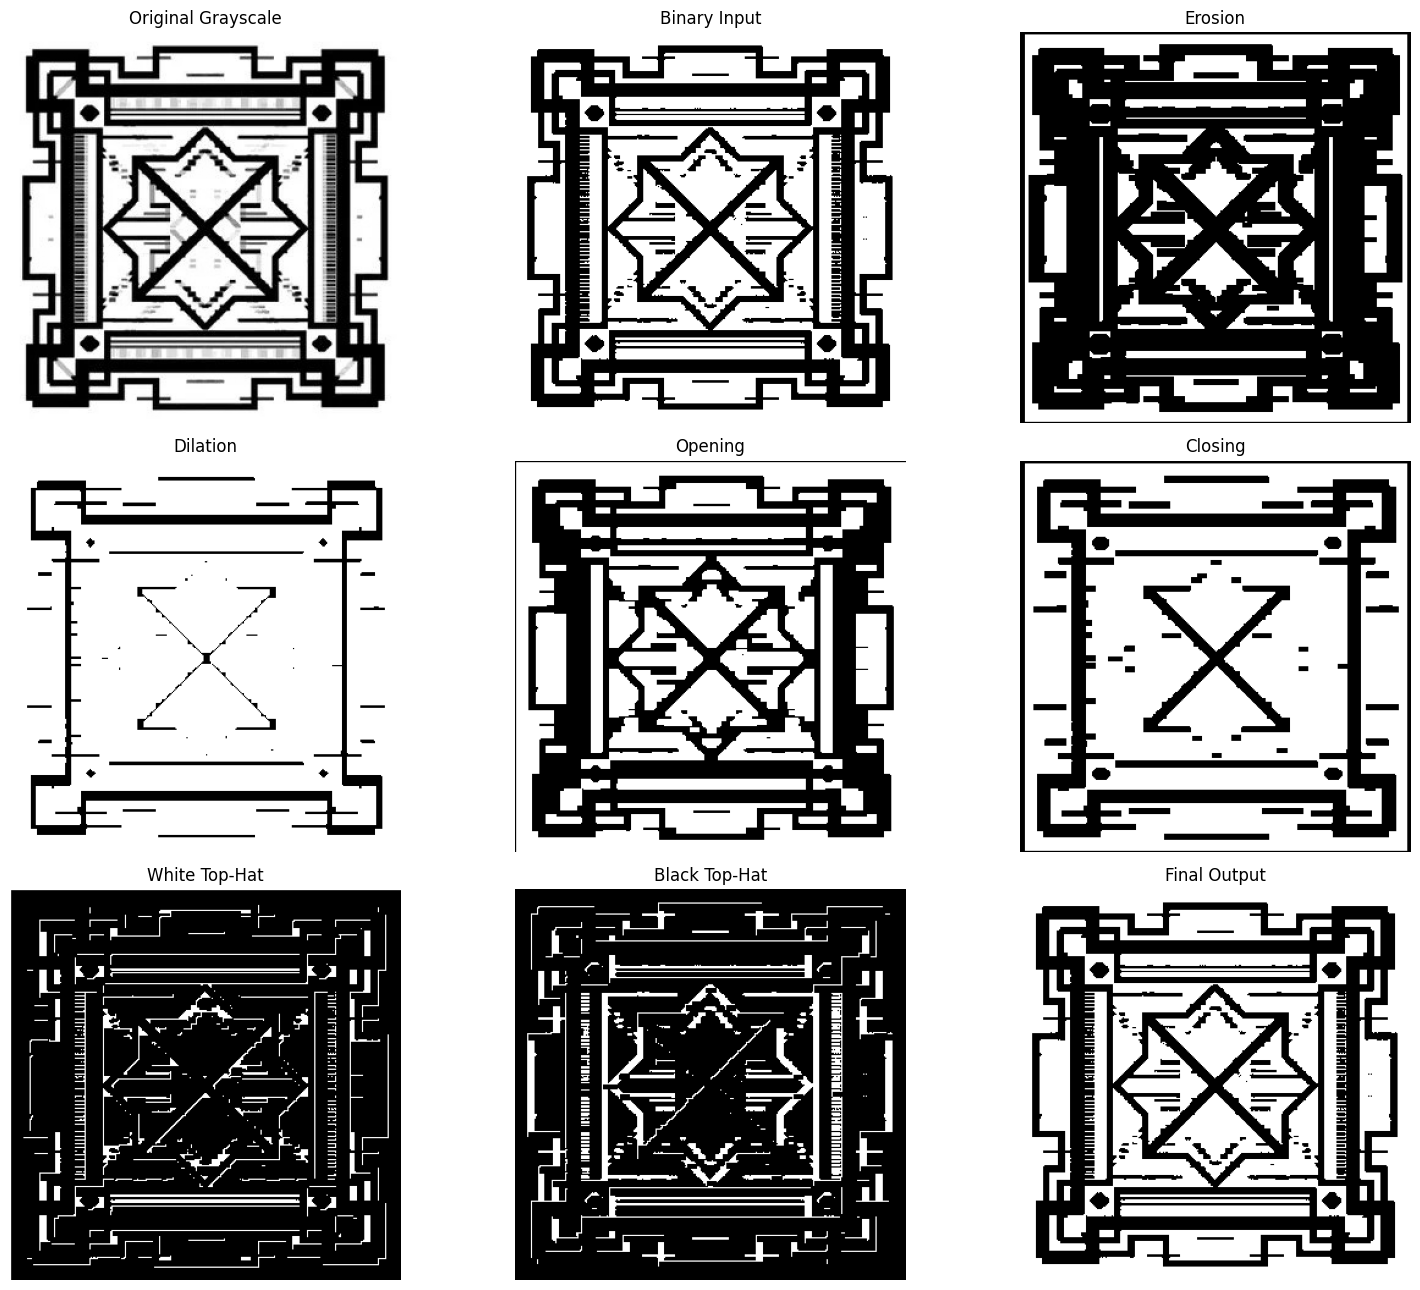

In [7]:
# ============================================================
# 9. Visualization
# ============================================================

def resize_for_display(
    image: np.ndarray,
    max_side: int = DISPLAY_MAX_SIDE
) -> np.ndarray:
    """
    Downsample only for notebook display when necessary.

    This does not modify the processing result.
    """
    height, width = image.shape[:2]
    largest_side = max(height, width)

    if largest_side <= max_side:
        return image

    scale = max_side / largest_side
    new_height = max(1, int(round(height * scale)))
    new_width = max(1, int(round(width * scale)))

    # Nearest-neighbor resize implemented directly so that
    # visualization does not depend on an image-processing library.
    row_indices = np.minimum(
        (np.arange(new_height) / scale).astype(int),
        height - 1
    )
    col_indices = np.minimum(
        (np.arange(new_width) / scale).astype(int),
        width - 1
    )

    return image[row_indices[:, None], col_indices[None, :]]


def display_pipeline(
    original_gray: np.ndarray,
    binary: np.ndarray,
    erosion: np.ndarray,
    dilation: np.ndarray,
    opening: np.ndarray,
    closing: np.ndarray,
    wth: np.ndarray,
    bth: np.ndarray,
    final_output: np.ndarray,
    processing_mode: str
) -> None:
    """
    Display the complete processing pipeline.
    """
    images = [
        original_gray,
        binary,
        erosion,
        dilation,
        opening,
        closing,
        wth,
        bth,
        final_output,
    ]

    titles = [
        "Original Grayscale",
        "Binary Input",
        "Erosion",
        "Dilation",
        "Opening",
        "Closing",
        "White Top-Hat",
        "Black Top-Hat",
        "Final Output",
    ]

    plt.figure(figsize=(16, 13))

    for index, (image, title) in enumerate(
        zip(images, titles),
        start=1
    ):
        plt.subplot(3, 3, index)

        display_image = resize_for_display(image)

        if index == 1 or (
            processing_mode == "grayscale" and index >= 3
        ):
            plt.imshow(display_image, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(display_image, cmap="gray", vmin=0, vmax=1)

        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


display_pipeline(
    original_gray=GRAY_IMAGE,
    binary=BINARY_IMAGE,
    erosion=erosion_result,
    dilation=dilation_result,
    opening=opening_result,
    closing=closing_result,
    wth=white_tophat_result,
    bth=black_tophat_result,
    final_output=final_output,
    processing_mode=PROCESSING_MODE,
)


STRUCTURING ELEMENT COMPARISON
SE 3×8 | Opening=58,221 | Closing=71,058 | WTH=6,887 | BTH=11,594
SE 4×8 | Opening=57,062 | Closing=72,513 | WTH=10,555 | BTH=15,166
SE 5×8 | Opening=55,594 | Closing=73,187 | WTH=9,421 | BTH=14,130
SE 6×8 | Opening=54,622 | Closing=77,943 | WTH=12,443 | BTH=20,140


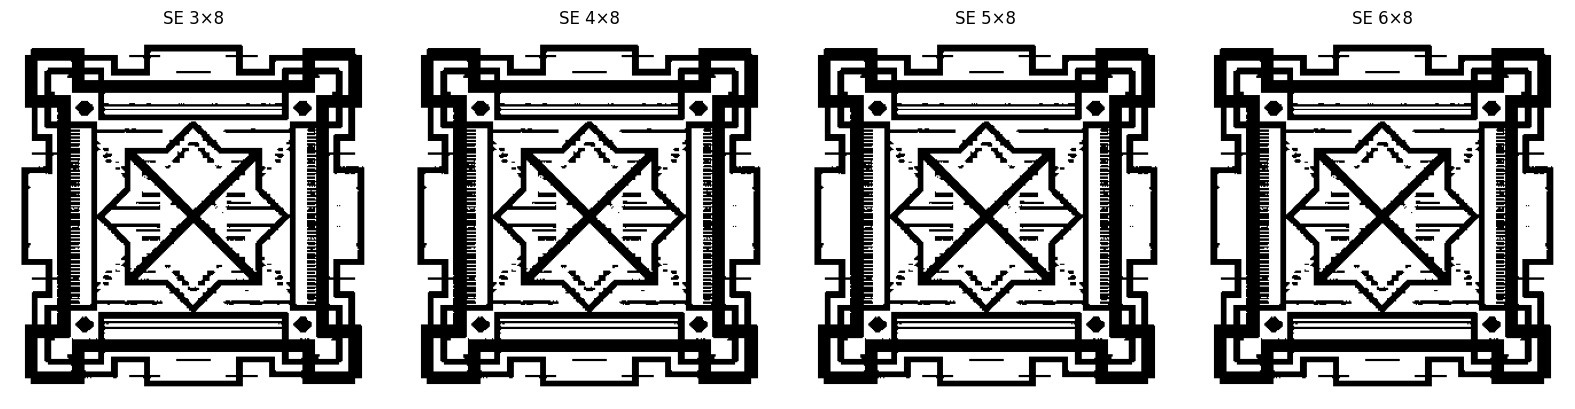

In [8]:
# ============================================================
# 10. Structuring Element Comparison
# ============================================================

def run_binary_pipeline(
    image: np.ndarray,
    se_shape: Tuple[int, int]
) -> Dict[str, np.ndarray]:
    """
    Run the complete binary morphological pipeline for one SE.
    """
    se = rectangular_structuring_element(
        se_shape[0],
        se_shape[1]
    )

    processor = MathematicalMorphology(se)

    opening = processor.opening_binary(image)
    closing = processor.closing_binary(image)
    wth = processor.white_top_hat_binary(image)
    bth = processor.black_top_hat_binary(image)
    output = processor.recombine_binary(image)

    return {
        "opening": opening,
        "closing": closing,
        "wth": wth,
        "bth": bth,
        "output": output,
    }


comparison_results = {}

for se_shape in REFERENCE_SE_CANDIDATES:
    comparison_results[se_shape] = run_binary_pipeline(
        BINARY_IMAGE,
        se_shape
    )

print("=" * 72)
print("STRUCTURING ELEMENT COMPARISON")
print("=" * 72)

for se_shape, result in comparison_results.items():
    opening_pixels = int(np.count_nonzero(result["opening"]))
    closing_pixels = int(np.count_nonzero(result["closing"]))
    wth_pixels = int(np.count_nonzero(result["wth"]))
    bth_pixels = int(np.count_nonzero(result["bth"]))

    print(
        f"SE {se_shape[0]}×{se_shape[1]} | "
        f"Opening={opening_pixels:,} | "
        f"Closing={closing_pixels:,} | "
        f"WTH={wth_pixels:,} | "
        f"BTH={bth_pixels:,}"
    )

# Visual comparison of final outputs for the paper's candidate SEs.
plt.figure(figsize=(16, 4))

for index, se_shape in enumerate(
    REFERENCE_SE_CANDIDATES,
    start=1
):
    plt.subplot(
        1,
        len(REFERENCE_SE_CANDIDATES),
        index
    )

    result = resize_for_display(
        comparison_results[se_shape]["output"]
    )

    plt.imshow(
        result,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    plt.title(f"SE {se_shape[0]}×{se_shape[1]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:
# ============================================================
# 11. Quantitative Verification and Sanity Checks
# ============================================================

def compare_arrays(
    actual: np.ndarray,
    expected: np.ndarray
) -> Dict[str, float]:
    """
    Pixel-wise comparison for validation and testing.
    """
    if actual.shape != expected.shape:
        raise ValueError("Arrays must have identical shapes.")

    difference = np.abs(
        actual.astype(np.int16)
        - expected.astype(np.int16)
    )

    mismatch_pixels = int(np.count_nonzero(difference))

    return {
        "mismatch_pixels": mismatch_pixels,
        "mismatch_rate_percent": (
            mismatch_pixels / actual.size * 100.0
        ),
        "maximum_difference": int(difference.max()),
    }


# The binary recombination should reconstruct the input exactly
# for the formulation used in the reference paper.
binary_recombination = MathematicalMorphology(
    rectangular_structuring_element(*PAPER_SE)
).recombine_binary(BINARY_IMAGE)

binary_recombination_check = compare_arrays(
    binary_recombination,
    BINARY_IMAGE
)

print("=" * 72)
print("SANITY CHECKS")
print("=" * 72)

print(
    "Binary recombination check:",
    binary_recombination_check
)

if binary_recombination_check["mismatch_pixels"] == 0:
    print("PASS: Binary IM + WTH − BTH reconstructs the input exactly.")
else:
    print("CHECK: Binary recombination differs from the input.")

# Verify algebraic ordering of compound operations.
paper_processor = MathematicalMorphology(
    rectangular_structuring_element(*PAPER_SE)
)

opening_direct = paper_processor.opening_binary(BINARY_IMAGE)
opening_manual = paper_processor.dilation_binary(
    paper_processor.erosion_binary(BINARY_IMAGE)
)

closing_direct = paper_processor.closing_binary(BINARY_IMAGE)
closing_manual = paper_processor.erosion_binary(
    paper_processor.dilation_binary(BINARY_IMAGE)
)

opening_check = compare_arrays(opening_direct, opening_manual)
closing_check = compare_arrays(closing_direct, closing_manual)

print(f"Opening consistency check: {opening_check}")
print(f"Closing consistency check: {closing_check}")

print("\nNo OpenCV/SciPy morphology operation is used by the core implementation.")


SANITY CHECKS
Binary recombination check: {'mismatch_pixels': 0, 'mismatch_rate_percent': 0.0, 'maximum_difference': 0}
PASS: Binary IM + WTH − BTH reconstructs the input exactly.
Opening consistency check: {'mismatch_pixels': 0, 'mismatch_rate_percent': 0.0, 'maximum_difference': 0}
Closing consistency check: {'mismatch_pixels': 0, 'mismatch_rate_percent': 0.0, 'maximum_difference': 0}

No OpenCV/SciPy morphology operation is used by the core implementation.


## 12. Results and Analysis

### Input

The notebook accepts an image selected at runtime. The filename and image dimensions are detected automatically, so the experiment is not tied to a fixed filename such as `Input_image.jpg`.

### Erosion

Erosion reduces foreground structures according to the active positions of the structuring element (SE). Foreground regions that cannot contain the required SE configuration are removed.

### Dilation

Dilation expands foreground structures according to the active SE positions. It can also connect nearby foreground regions when the selected SE spans the gap between them.

### Opening

Opening consists of erosion followed by dilation:

```text
Opening = Erosion → Dilation
```

It removes small foreground structures or protrusions relative to the selected SE while preserving larger structures.

### Closing

Closing consists of dilation followed by erosion:

```text
Closing = Dilation → Erosion
```

It can fill small background gaps and connect nearby foreground regions according to the selected SE.

### White Top-Hat

```text
WTH = IM − Opening
```

The White Top-Hat result represents foreground information removed by the opening operation.

### Black Top-Hat

```text
BTH = Closing − IM
```

The Black Top-Hat result represents background information or dark structures that are filled or suppressed by the closing operation.

### Final Mathematical Morphological Output

```text
Output = IM + WTH − BTH
```

In the reference paper's binary formulation, this recombination can reconstruct the original binary image. Therefore, the structural effects of the morphological processing are primarily observed in the intermediate **erosion, dilation, opening, closing, WTH, and BTH** results.

### Structuring-Element Comparison

The reference experiment evaluates rectangular structuring elements including `3 × 8`, `4 × 8`, `5 × 8`, and `6 × 8`. The notebook reproduces this comparison while also providing an adaptive SE configuration for images with different resolutions.

The effect and suitability of a structuring element are **image-dependent**. The `4 × 8` SE is therefore treated as the primary reference configuration rather than being presented as a universally optimal kernel.

### Dynamic-Image Improvement

The adaptive configuration derives the SE dimensions from the input image resolution instead of assuming that every image has the same dimensions as the reference image.

This improves the reusability of the implementation by maintaining an approximately consistent SE aspect ratio while applying practical size bounds for different image resolutions.

### Grayscale Extension

The optional grayscale mode performs morphological operations directly on intensity values rather than converting the image to a binary representation.

In this mode, erosion and dilation operate using intensity minima and maxima over the active SE positions. This allows morphological effects to be examined while retaining grayscale information and provides an additional configuration for photographic or uneven-illumination images.

The grayscale and adaptive configurations are **engineering extensions of the implementation** and are reported separately from the primary binary paper-reproduction experiment.


## 13. Conclusion

This notebook implements the mathematical morphological workflow described in the reference paper while extending the implementation for reusable image processing across different input files and image resolutions.

The main features and improvements are:

1. **Dynamic image input** — no fixed filename is required.

2. **Custom Otsu thresholding** — binary threshold selection is implemented independently rather than relying on OpenCV thresholding.

3. **Custom erosion and dilation** — the core morphological operations are implemented directly without calling built-in morphology functions from image-processing libraries.

4. **Custom opening and closing** — compound operations are constructed from the implemented erosion and dilation functions.

5. **Custom White and Black Top-Hat transformations** — WTH and BTH are implemented directly from the corresponding morphological definitions.

6. **Reference 4 × 8 SE configuration** — the fixed rectangular SE remains available for paper-oriented reproduction.

7. **Adaptive SE configuration** — the structuring element can be scaled according to input image dimensions.

8. **Structuring-element comparison** — the `3 × 8`, `4 × 8`, `5 × 8`, and `6 × 8` configurations are retained for experimental comparison.

9. **Grayscale morphology extension** — grayscale processing is provided as a separate implementation extension and is not presented as part of the paper's binary experiment.

10. **Quantitative verification** — sanity checks are included to verify the consistency of the implemented morphological operations and final recombination.

Overall, the notebook provides a custom and reusable implementation of binary mathematical morphology while maintaining a clear distinction between the **reference-paper methodology** and the **additional engineering extensions**.

### Academic Integrity Note

The reported primary experiment is based on the methodology presented in the reference paper. **Dynamic SE selection and grayscale morphology are implementation extensions** and should not be interpreted as methods used in the original 2016 paper.


## 14. Reference

K. A. M. Said and A. B. Jambek, “A Study on Image Processing Using Mathematical Morphological,” *2016 3rd International Conference on Electronic Design (ICED)*, Phuket, Thailand, 11–12 August 2016.

### Key Equations from the Reference

```text
Final Mathematical Morphological Output = IM + WTH − BTH

WTH = IM − Opening

BTH = Closing − IM

Opening = IM ⊖ SE ⊕ SE

Closing = IM ⊕ SE ⊖ SE
```

The reference experiment applies mathematical morphology using **rectangular structuring elements** and evaluates different SE configurations to determine a suitable SE for its specific input image.

The implementation in this repository follows the reference paper's **binary morphological workflow**, while the adaptive SE configuration and grayscale processing are provided as additional engineering extensions.
